In [16]:
# Prepare environment
from pathlib import Path
import pandas as pd
import geopandas as gpd
import seaborn as sns
import matplotlib.pyplot as plt

#Set file paths
root_fldr = Path.cwd().parent
raw_fldr = root_fldr/"data"/"raw"
processed_fldr = root_fldr/'data'/'processed'
prescribed_burns_cleaned = gpd.read_file(processed_fldr / "prescribed_burns.gpkg")
inaturalist_gdf_cleaned = gpd.read_file(processed_fldr / "inaturalist_gdf_cleaned.gpkg")

In [20]:
#Filter out plant observations that don't intersect fires
fire_plants_mask = inaturalist_gdf_cleaned.intersects(prescribed_burns_cleaned.geometry.union_all()) 

fire_plants_mask.value_counts()

False    145695
True       1731
Name: count, dtype: int64

In [21]:
fire_plants = inaturalist_gdf_cleaned[fire_plants_mask]

array([[<Axes: title={'center': 'observation_date'}>]], dtype=object)

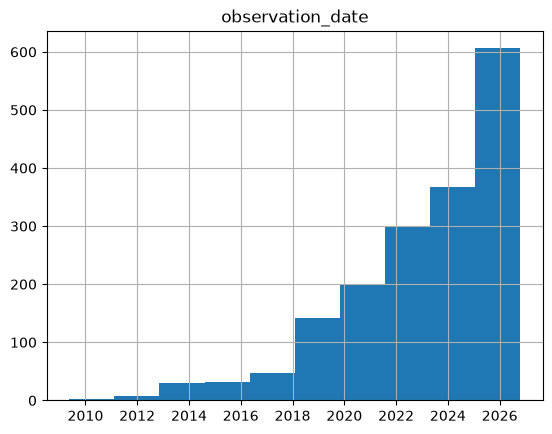

In [ ]:
fire_plants.hist("observation_date");

In [26]:
prescribed_burns_cleaned["year"].value_counts()

year
2023    1190
2019    1054
2025     982
2024     949
2020     732
2021     724
2022     634
2018     497
2017     258
2011     246
2010     221
2009     216
2013     170
2015     165
2012     121
2014     108
2016      78
Name: count, dtype: int64